# RW11 charging-instance diagnostic

Exploratory check of the NASA RW Matlab records for RW9, RW10, RW11, and RW12.

**Question.** Given a similar initial voltage, age, and temperature, do the four cells then follow the same charge-current trajectory, or does RW11 systematically follow a different one?

This notebook only reads the dataset. It does not change the digital twin, the reward, the search, or any saved optimization result.


## 1. Objective

A charge instance is one `charge (random walk)` step: a short, nearly constant-current charge pulse inside the room-temperature random-walk test.

For every such step the initial state is the first sample:

- voltage, as recorded
- temperature, as recorded
- age, which the Matlab file does not store as a sensor. Age here is the life fraction `step_index / (n_steps - 1)`, the same step-order definition used when the twin series were built. Elapsed hours from the start of that cell's test are stored beside it.

Two instances are comparable when all three of voltage, temperature, and age fall inside the tolerances in the next cell. Exact numeric equality is counted separately and is not required.

The future trajectory is the current, voltage, and temperature after that first sample, aligned on a common relative-time grid.


In [1]:
from __future__ import annotations

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.io import loadmat
from scipy.spatial import cKDTree

# --- paths -----------------------------------------------------------------
MATLAB_DIR = Path(
    "/data/battery_RW_NASA/NASA_RW/dataset/"
    "Battery_Uniform_Distribution_Charge_Discharge_DataSet_2Post/"
    "Battery_Uniform_Distribution_Charge_Discharge_DataSet_2Post/data/Matlab"
)
OUTPUT_DIR = Path("/data/battery_RW_NASA/eda/outputs")
FIGURE_DIR = Path("/data/battery_RW_NASA/eda/figures")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

CELLS = ["RW9", "RW10", "RW11", "RW12"]
OTHERS = ["RW9", "RW10", "RW12"]  # the three cells RW11 is compared with
CHARGE_COMMENT = "charge (random walk)"

# --- matching tolerances (edit these) --------------------------------------
# A partner matches when EVERY condition holds:
#   |V - V_ref| <= TOL_VOLTAGE_V
#   |T - T_ref| <= TOL_TEMPERATURE_C
#   |age - age_ref| <= TOL_AGE
TOL_VOLTAGE_V = 0.02          # 20 mV
TOL_TEMPERATURE_C = 1.0       # 1 °C
TOL_AGE = 0.02                # 2% of the cell's step-order life

# Stricter band, reported as "exact" but still a tolerance, not float equality.
EXACT_VOLTAGE_V = 0.001       # 1 mV
EXACT_TEMPERATURE_C = 0.05    # 0.05 °C
EXACT_AGE = 1e-4              # 0.01% of life

# --- alignment --------------------------------------------------------------
FUTURE_WINDOW_S = 120.0       # compare this many seconds after the initial sample
RESAMPLE_DT_S = 1.0           # common grid, because raw steps are about 1 Hz
MIN_OVERLAP_SAMPLES = 30      # below this, the current comparison is not scored

# --- RW11 flag --------------------------------------------------------------
# Current flag uses the overlap window only. Duration is reported separately
# so a longer pulse at the same current is not called a different profile.
RW11_CURRENT_RMSE_A = 0.25
RW11_MEAN_CURRENT_DIFF_A = 0.25
DURATION_DIFF_S = 30.0

# Data-quality fences. Counts above these are reported; rows are not dropped.
ABRUPT_CURRENT_JUMP_A = 1.0
ABNORMAL_ABS_CURRENT_A = 6.0
DT_OFF_NOMINAL_S = 0.05       # |dt - 1 s| above this is an irregular sample

CELL_COLOR = {"RW9": "#4C78A8", "RW10": "#F58518", "RW11": "#E45756", "RW12": "#54A24B"}
plt.rcParams.update({"figure.dpi": 120, "axes.grid": True, "grid.alpha": 0.3})

print("Tolerances: V <=", TOL_VOLTAGE_V, "V | T <=", TOL_TEMPERATURE_C, "°C | age <=", TOL_AGE)
print("Future window:", FUTURE_WINDOW_S, "s at", RESAMPLE_DT_S, "s")
print("RW11 current flag: RMSE >", RW11_CURRENT_RMSE_A, "A or |mean I difference| >", RW11_MEAN_CURRENT_DIFF_A, "A")


Tolerances: V <= 0.02 V | T <= 1.0 °C | age <= 0.02
Future window: 120.0 s at 1.0 s
RW11 current flag: RMSE > 0.25 A or |mean I difference| > 0.25 A


## 2. Dataset loading

Each `RW*.mat` file is one cell. `data.step` is the chronological list of protocol steps. A step carries `voltage`, `current`, `temperature`, `time`, `relativeTime`, `type`, and `comment`.

Charge current in this recording is positive in these random-walk charge steps (the optimization stack uses the opposite NASA sign during rollout). This notebook keeps the sign as stored in the Matlab file and also reports the magnitude.


In [2]:
def _text(raw) -> str:
    if isinstance(raw, np.ndarray):
        if raw.size == 0:
            return ""
        raw = raw.flat[0]
    if isinstance(raw, bytes):
        raw = raw.decode("utf-8", errors="replace")
    return str(raw).strip().lower()


def _resample(time_s: np.ndarray, values: np.ndarray, grid: np.ndarray) -> np.ndarray:
    """Linear interpolation onto `grid` seconds after the first sample.

    Samples past the end of the step are NaN. They are not filled and not dropped
    from the match; later cells score only the overlapping finite prefix.
    """
    t = np.asarray(time_s, dtype=np.float64)
    y = np.asarray(values, dtype=np.float64)
    if t.size == 0 or y.size == 0:
        return np.full(grid.shape, np.nan, dtype=np.float32)
    t = t - t[0]
    mask = np.isfinite(t) & np.isfinite(y)
    t, y = t[mask], y[mask]
    if t.size < 2:
        return np.full(grid.shape, np.nan, dtype=np.float32)
    keep = np.concatenate([[True], np.diff(t) > 1e-6])
    t, y = t[keep], y[keep]
    if t.size < 2:
        return np.full(grid.shape, np.nan, dtype=np.float32)
    out = np.interp(grid, t, y).astype(np.float32)
    out[grid > t[-1] + 1e-6] = np.nan
    out[grid < t[0] - 1e-6] = np.nan
    return out


def _current_level_count(current: np.ndarray) -> int:
    mag = np.abs(np.asarray(current, dtype=np.float64))
    mag = mag[np.isfinite(mag)]
    if mag.size == 0:
        return 0
    rounded = np.round(mag * 10.0) / 10.0
    changes = np.concatenate([[True], np.abs(np.diff(rounded)) > 1e-9])
    return int(changes.sum())


def load_cell(cell: str, grid: np.ndarray) -> tuple[pd.DataFrame, dict[str, np.ndarray], dict]:
    path = MATLAB_DIR / f"{cell}.mat"
    raw = loadmat(str(path), squeeze_me=True, struct_as_record=False)["data"]
    steps = list(raw.step)
    n_steps = len(steps)
    t_origin = float(np.asarray(steps[0].time, dtype=np.float64).ravel()[0])
    t_end = float(np.asarray(steps[-1].time, dtype=np.float64).ravel()[-1])
    life_s = max(t_end - t_origin, 1.0)

    comment_counts: dict[str, int] = {}
    n_nan = {"voltage": 0, "current": 0, "temperature": 0}
    n_samples = 0
    n_dup_time_steps = 0
    n_irregular_steps = 0
    dt_samples = []
    charge_rows = []
    win_i, win_v, win_t = [], [], []
    n_short_charge = 0
    n_abrupt = 0
    n_abnormal_i = 0
    v_span = [np.inf, -np.inf]
    t_span = [np.inf, -np.inf]
    i_abs_max = 0.0

    for index, step in enumerate(steps):
        comment = _text(step.comment)
        comment_counts[comment] = comment_counts.get(comment, 0) + 1
        voltage = np.asarray(step.voltage, dtype=np.float64).ravel()
        current = np.asarray(step.current, dtype=np.float64).ravel()
        temperature = np.asarray(step.temperature, dtype=np.float64).ravel()
        time_s = np.asarray(step.time, dtype=np.float64).ravel()
        n = int(voltage.size)
        if n == 0:
            continue
        n_samples += n
        n_nan["voltage"] += int(np.isnan(voltage).sum())
        n_nan["current"] += int(np.isnan(current).sum())
        n_nan["temperature"] += int(np.isnan(temperature).sum())
        finite_v = voltage[np.isfinite(voltage)]
        finite_t = temperature[np.isfinite(temperature)]
        finite_i = current[np.isfinite(current)]
        if finite_v.size:
            v_span[0] = min(v_span[0], float(finite_v.min()))
            v_span[1] = max(v_span[1], float(finite_v.max()))
        if finite_t.size:
            t_span[0] = min(t_span[0], float(finite_t.min()))
            t_span[1] = max(t_span[1], float(finite_t.max()))
        if finite_i.size:
            i_abs_max = max(i_abs_max, float(np.max(np.abs(finite_i))))
            n_abnormal_i += int(np.sum(np.abs(finite_i) > ABNORMAL_ABS_CURRENT_A))

        if time_s.size >= 2:
            dt = np.diff(time_s)
            dt = dt[np.isfinite(dt)]
            if dt.size:
                dt_samples.append(float(np.median(dt)))
                if np.any(np.abs(dt) <= 1e-6):
                    n_dup_time_steps += 1
                if np.mean(np.abs(dt - 1.0) > DT_OFF_NOMINAL_S) > 0.05:
                    n_irregular_steps += 1

        if comment != CHARGE_COMMENT or n < 2 or time_s.size < 2:
            continue
        duration = float(time_s[-1] - time_s[0])
        if duration < FUTURE_WINDOW_S:
            n_short_charge += 1
        di = np.diff(current)
        di = di[np.isfinite(di)]
        if di.size and np.any(np.abs(di) > ABRUPT_CURRENT_JUMP_A):
            n_abrupt += 1
        age = float(index / max(n_steps - 1, 1))
        elapsed_h = float((time_s[0] - t_origin) / 3600.0)
        mag = np.abs(current[np.isfinite(current)])
        charge_rows.append({
            "cell": cell,
            "local_index": len(charge_rows),
            "step_index": int(index),
            "n_samples": n,
            "duration_s": duration,
            "dt_median_s": float(np.median(np.diff(time_s))),
            "V_initial": float(voltage[0]),
            "T_initial": float(temperature[0]),
            "age_initial": age,
            "elapsed_h": elapsed_h,
            "I_initial": float(current[0]),
            "I_mean": float(np.mean(current[np.isfinite(current)])) if np.isfinite(current).any() else np.nan,
            "I_abs_mean": float(np.mean(mag)) if mag.size else np.nan,
            "I_abs_max": float(np.max(mag)) if mag.size else np.nan,
            "I_abs_min": float(np.min(mag)) if mag.size else np.nan,
            "n_current_levels": _current_level_count(current),
            "charge_ah": float(np.trapz(np.abs(current), time_s) / 3600.0) if n > 1 else np.nan,
        })
        win_i.append(_resample(time_s, current, grid))
        win_v.append(_resample(time_s, voltage, grid))
        win_t.append(_resample(time_s, temperature, grid))

    frame = pd.DataFrame(charge_rows)
    windows = {
        "current": np.vstack(win_i).astype(np.float32) if win_i else np.zeros((0, grid.size), np.float32),
        "voltage": np.vstack(win_v).astype(np.float32) if win_v else np.zeros((0, grid.size), np.float32),
        "temperature": np.vstack(win_t).astype(np.float32) if win_t else np.zeros((0, grid.size), np.float32),
    }
    quality = {
        "cell": cell,
        "n_steps": n_steps,
        "n_samples": n_samples,
        "life_hours": life_s / 3600.0,
        "n_charge_random_walk": int(len(frame)),
        "n_nan_voltage": n_nan["voltage"],
        "n_nan_current": n_nan["current"],
        "n_nan_temperature": n_nan["temperature"],
        "n_steps_with_duplicate_timestamps": n_dup_time_steps,
        "n_steps_with_irregular_dt": n_irregular_steps,
        "dt_median_s": float(np.median(dt_samples)) if dt_samples else np.nan,
        "charge_duration_median_s": float(frame["duration_s"].median()) if len(frame) else np.nan,
        "n_charge_shorter_than_window": n_short_charge,
        "n_charge_with_abrupt_current_jump": n_abrupt,
        "n_samples_abs_current_above_fence": n_abnormal_i,
        "voltage_min": v_span[0],
        "voltage_max": v_span[1],
        "temperature_min": t_span[0],
        "temperature_max": t_span[1],
        "abs_current_max": i_abs_max,
        "comment_counts": comment_counts,
    }
    return frame, windows, quality


GRID = np.arange(0.0, FUTURE_WINDOW_S + 0.5 * RESAMPLE_DT_S, RESAMPLE_DT_S)
print("Loading four cells...")
INSTANCES = {}
WINDOWS = {}
QUALITY = []
for cell in CELLS:
    frame, windows, quality = load_cell(cell, GRID)
    INSTANCES[cell] = frame
    WINDOWS[cell] = windows
    QUALITY.append(quality)
    print(f"  {cell}: {len(frame)} charge steps, life {quality['life_hours']:.0f} h, "
          f"median charge duration {quality['charge_duration_median_s']:.0f} s")


Loading four cells...


  RW9: 23416 charge steps, life 3531 h, median charge duration 164 s


  RW10: 23159 charge steps, life 3534 h, median charge duration 188 s


  RW11: 22759 charge steps, life 3534 h, median charge duration 213 s


  RW12: 21693 charge steps, life 3536 h, median charge duration 300 s


## 3. Dataset structure and variables

`procedure` on these files is a uniform random-walk charge and discharge at room temperature. The step comments below separate random-walk pulses from reference cycles and the two low-current OCV sweeps.

Age is not a recorded channel. Within one charge step it does not change, because it is the index of that step in the cell's life. Voltage and temperature do change along the step and are compared on the relative-time grid.


In [3]:
comment_table = []
for quality in QUALITY:
    row = {"cell": quality["cell"], "n_steps": quality["n_steps"], "life_hours": round(quality["life_hours"], 1)}
    for name, count in sorted(quality["comment_counts"].items(), key=lambda kv: -kv[1])[:8]:
        row[name] = count
    comment_table.append(row)
comment_df = pd.DataFrame(comment_table).set_index("cell")
display(comment_df)

initial_summary = []
for cell in CELLS:
    frame = INSTANCES[cell]
    initial_summary.append({
        "cell": cell,
        "n_charge_steps": len(frame),
        "V_initial_median": frame["V_initial"].median(),
        "T_initial_median": frame["T_initial"].median(),
        "T_initial_min": frame["T_initial"].min(),
        "T_initial_max": frame["T_initial"].max(),
        "age_median": frame["age_initial"].median(),
        "duration_median_s": frame["duration_s"].median(),
        "I_abs_mean_of_means": frame["I_abs_mean"].mean(),
        "median_current_levels": frame["n_current_levels"].median(),
    })
initial_df = pd.DataFrame(initial_summary).set_index("cell")
display(initial_df.round(3))


,n_steps,life_hours,rest (random walk),discharge (random walk),charge (random walk),pulsed load (rest),pulsed load (discharge),pulsed charge (rest),pulsed charge (charge),reference charge
cell,,,,,,,,,,
RW9,113578,3531.5,56342,28221,28119,184,184,114,114,80
RW10,110818,3534.4,54966,27557,27407,183,183,118,118,77
RW11,109389,3533.8,54244,27176,27066,186,186,122,122,77
RW12,110013,3536.0,54517,27273,27241,206,206,146,146,76


,n_charge_steps,V_initial_median,T_initial_median,T_initial_min,T_initial_max,age_median,duration_median_s,I_abs_mean_of_means,median_current_levels
cell,,,,,,,,,
RW9,23416,3.982,34.674,21.201,46.591,0.480,163.705,2.393,1.0
RW10,23159,3.984,34.113,21.384,45.636,0.479,187.940,2.399,1.0
RW11,22759,3.980,25.883,19.025,38.716,0.482,212.520,2.400,1.0
RW12,21693,3.994,26.389,18.164,38.753,0.479,299.960,2.315,1.0


## 4. Data quality check

Nothing in this section removes a charge step from the match. Short steps, irregular sample intervals, and current jumps are counted so a later RW11 difference can be checked against a recording problem.


In [4]:
quality_rows = []
for quality in QUALITY:
    quality_rows.append({
        "cell": quality["cell"],
        "samples": quality["n_samples"],
        "NaN V/I/T": f"{quality['n_nan_voltage']}/{quality['n_nan_current']}/{quality['n_nan_temperature']}",
        "steps with duplicate time": quality["n_steps_with_duplicate_timestamps"],
        "steps with irregular dt": quality["n_steps_with_irregular_dt"],
        "median dt (s)": quality["dt_median_s"],
        "charge steps shorter than window": quality["n_charge_shorter_than_window"],
        "charge steps with |dI| > 1 A": quality["n_charge_with_abrupt_current_jump"],
        "samples with |I| > 6 A": quality["n_samples_abs_current_above_fence"],
        "V range": f"{quality['voltage_min']:.2f}–{quality['voltage_max']:.2f}",
        "T range (°C)": f"{quality['temperature_min']:.1f}–{quality['temperature_max']:.1f}",
        "|I| max (A)": round(quality["abs_current_max"], 2),
    })
quality_df = pd.DataFrame(quality_rows).set_index("cell")
display(quality_df)
quality_df.to_csv(OUTPUT_DIR / "rw11_data_quality_summary.csv")
print("Wrote", OUTPUT_DIR / "rw11_data_quality_summary.csv")


,samples,NaN V/I/T,steps with duplicate time,steps with irregular dt,median dt (s),charge steps shorter than window,charge steps with |dI| > 1 A,samples with |I| > 6 A,V range,T range (°C),|I| max (A)
cell,,,,,,,,,,,
RW9,8532073,0/0/0,1715,65429,1.0,10809,0,0,2.79–4.66,18.9–46.6,4.80
RW10,8596025,0/0/0,1777,63725,1.0,10467,0,0,2.78–4.66,18.7–45.6,4.62
RW11,8664510,0/0/0,1653,62672,1.0,9960,0,0,2.78–4.65,17.2–38.7,4.66
RW12,8638882,0/0/0,3590,60748,1.0,9010,0,0,2.59–4.81,17.4–38.8,4.62


Wrote /data/battery_RW_NASA/eda/outputs/rw11_data_quality_summary.csv


## 5. Charging instance identification

The matched population is only `charge (random walk)`. Reference charges and pulsed-charge steps are a different protocol, so mixing them into the initial-condition match would make the current shape differ for a procedural reason.

Each random-walk charge step is one instance. Its initial state is sample 0. Its future trajectory is every later sample in that step.


In [5]:
for cell in CELLS:
    frame = INSTANCES[cell]
    print(
        f"{cell}: {len(frame)} instances | "
        f"duration p10/p50/p90 = "
        f"{frame['duration_s'].quantile(0.1):.0f}/"
        f"{frame['duration_s'].median():.0f}/"
        f"{frame['duration_s'].quantile(0.9):.0f} s | "
        f"share with a single current level = "
        f"{(frame['n_current_levels'] == 1).mean():.1%}"
    )


RW9: 23416 instances | duration p10/p50/p90 = 1/164/300 s | share with a single current level = 51.7%
RW10: 23159 instances | duration p10/p50/p90 = 1/188/300 s | share with a single current level = 52.3%
RW11: 22759 instances | duration p10/p50/p90 = 2/213/300 s | share with a single current level = 50.2%
RW12: 21693 instances | duration p10/p50/p90 = 0/300/300 s | share with a single current level = 51.5%


## 6. Initial condition matching

RW9 is the reference list. For each RW9 charge step, RW10, RW11, and RW12 are searched for a step inside the voltage, temperature, and age tolerances at the same time. The search uses a Chebyshev ball: after dividing each variable by its tolerance, the partner must lie inside a cube of radius 1.

When several partners qualify, the nearest unused partner is kept. Each charge step is used in at most one quadruple, and tighter quadruples are kept first. This is a tolerance match, not an exact match. A quadruple is also labeled exact when the four-cell range is inside the stricter exact band.


In [6]:
def _scaled(frame: pd.DataFrame) -> np.ndarray:
    scale = np.array([TOL_VOLTAGE_V, TOL_TEMPERATURE_C, TOL_AGE], dtype=np.float64)
    return np.column_stack([
        frame["V_initial"].to_numpy(),
        frame["T_initial"].to_numpy(),
        frame["age_initial"].to_numpy(),
    ]) / scale


scaled = {cell: _scaled(INSTANCES[cell]) for cell in CELLS}
trees = {cell: cKDTree(scaled[cell]) for cell in ["RW10", "RW11", "RW12"]}
partner_lists = {cell: [] for cell in ["RW10", "RW11", "RW12"]}
n9 = len(INSTANCES["RW9"])
for point in scaled["RW9"]:
    for cell in ["RW10", "RW11", "RW12"]:
        inds = trees[cell].query_ball_point(point, r=1.0, p=np.inf)
        if not inds:
            partner_lists[cell].append([])
            continue
        delta = np.max(np.abs(scaled[cell][inds] - point), axis=1)
        order = np.argsort(delta)
        partner_lists[cell].append([(float(delta[k]), int(inds[k])) for k in order])

candidates = []
n_with_any_partner = 0
for i in range(n9):
    lists = [partner_lists[cell][i] for cell in ["RW10", "RW11", "RW12"]]
    if all(lists):
        n_with_any_partner += 1
        candidates.append((sum(item[0][0] for item in lists), i))
candidates.sort()

used = {cell: set() for cell in CELLS}
assigned = []
for _, i9 in candidates:
    if i9 in used["RW9"]:
        continue
    chosen = {}
    available = True
    for cell in ["RW10", "RW11", "RW12"]:
        pick = next((pair for pair in partner_lists[cell][i9] if pair[1] not in used[cell]), None)
        if pick is None:
            available = False
            break
        chosen[cell] = pick[1]
    if not available:
        continue
    used["RW9"].add(i9)
    for cell, local in chosen.items():
        used[cell].add(local)
    assigned.append({"RW9": i9, **chosen})

print(f"RW9 charge steps: {n9}")
print(f"RW9 steps with at least one in-tolerance partner in every other cell: {n_with_any_partner}")
print(f"Exclusive quadruples kept: {len(assigned)}")
print("Unused charge steps after matching:")
for cell in CELLS:
    print(f"  {cell}: {len(INSTANCES[cell]) - len(used[cell])} unmatched")


RW9 charge steps: 23416
RW9 steps with at least one in-tolerance partner in every other cell: 3332
Exclusive quadruples kept: 2003
Unused charge steps after matching:
  RW9: 21413 unmatched
  RW10: 21156 unmatched
  RW11: 20756 unmatched
  RW12: 19690 unmatched


## 7. Future current alignment

Alignment is relative to the matched initial sample, not to the original test clock.

1. Subtract the step's first timestamp.
2. Interpolate current, voltage, and temperature onto `0, 1, 2, ... , 120` seconds.
3. Where a step ends before 120 s, the remaining grid is NaN.
4. Profile RMSE uses only the prefix where all four cells still have a sample. That prefix length is reported and is never silently replaced.

Full-step duration is kept as its own column. It is not forced onto the 120 s window.


In [7]:
def _range(values: list[float]) -> float:
    return float(max(values) - min(values))


def _rmse(a: np.ndarray, b: np.ndarray) -> float:
    mask = np.isfinite(a) & np.isfinite(b)
    if mask.sum() < MIN_OVERLAP_SAMPLES:
        return np.nan
    err = a[mask] - b[mask]
    return float(np.sqrt(np.mean(err ** 2)))


records = []
for match_id, local in enumerate(assigned, start=1):
    series = {}
    meta = {}
    for cell in CELLS:
        row = INSTANCES[cell].iloc[local[cell]]
        meta[cell] = row
        series[cell] = {name: WINDOWS[cell][name][local[cell]] for name in ("current", "voltage", "temperature")}
    overlap = np.ones(GRID.size, dtype=bool)
    for cell in CELLS:
        overlap &= np.isfinite(series[cell]["current"])
    n_overlap = int(overlap.sum())
    overlap_s = float(n_overlap * RESAMPLE_DT_S)

    def _overlap_stats(cell: str) -> dict:
        current = series[cell]["current"][overlap] if n_overlap else np.array([])
        return {
            "I_mean_window": float(np.mean(current)) if current.size else np.nan,
            "I_abs_mean_window": float(np.mean(np.abs(current))) if current.size else np.nan,
            "I_abs_max_window": float(np.max(np.abs(current))) if current.size else np.nan,
            "I_abs_min_window": float(np.min(np.abs(current))) if current.size else np.nan,
        }

    stats = {cell: _overlap_stats(cell) for cell in CELLS}
    ref_current = np.nanmean(np.vstack([series[cell]["current"] for cell in OTHERS]), axis=0)
    ref_voltage = np.nanmean(np.vstack([series[cell]["voltage"] for cell in OTHERS]), axis=0)
    ref_temperature = np.nanmean(np.vstack([series[cell]["temperature"] for cell in OTHERS]), axis=0)
    i_rmse = _rmse(series["RW11"]["current"], ref_current)
    v_rmse = _rmse(series["RW11"]["voltage"], ref_voltage)
    t_rmse = _rmse(series["RW11"]["temperature"], ref_temperature)
    i_mean_gap = abs(stats["RW11"]["I_mean_window"] - np.nanmean([stats[c]["I_mean_window"] for c in OTHERS]))
    duration_gap = abs(float(meta["RW11"]["duration_s"]) - float(np.median([meta[c]["duration_s"] for c in OTHERS])))

    voltages = [float(meta[c]["V_initial"]) for c in CELLS]
    temps = [float(meta[c]["T_initial"]) for c in CELLS]
    ages = [float(meta[c]["age_initial"]) for c in CELLS]
    exact = (
        _range(voltages) <= EXACT_VOLTAGE_V
        and _range(temps) <= EXACT_TEMPERATURE_C
        and _range(ages) <= EXACT_AGE
    )
    scored = n_overlap >= MIN_OVERLAP_SAMPLES and np.isfinite(i_rmse)
    if not scored:
        flag = "INSUFFICIENT_OVERLAP"
    elif i_rmse > RW11_CURRENT_RMSE_A or i_mean_gap > RW11_MEAN_CURRENT_DIFF_A:
        flag = "RW11_DIFFERENT"
    else:
        flag = "RW11_SIMILAR"

    record = {
        "match_id": match_id,
        "match_type": "exact" if exact else "tolerance",
        "n_overlap_samples": n_overlap,
        "overlap_s": overlap_s,
        "V_range": _range(voltages),
        "T_range": _range(temps),
        "age_range": _range(ages),
        "RW11_current_rmse_A": i_rmse,
        "RW11_voltage_rmse_V": v_rmse,
        "RW11_temperature_rmse_C": t_rmse,
        "RW11_mean_current_gap_A": i_mean_gap,
        "RW11_duration_gap_s": duration_gap,
        "RW11_flag": flag,
        "duration_different": bool(duration_gap > DURATION_DIFF_S),
    }
    for cell in CELLS:
        row = meta[cell]
        record[f"{cell}_index"] = int(row["step_index"])
        record[f"{cell}_local"] = int(row["local_index"])
        record[f"V_initial_{cell}"] = float(row["V_initial"])
        record[f"T_initial_{cell}"] = float(row["T_initial"])
        record[f"Age_initial_{cell}"] = float(row["age_initial"])
        record[f"elapsed_h_{cell}"] = float(row["elapsed_h"])
        record[f"I_initial_{cell}"] = float(row["I_initial"])
        record[f"I_mean_{cell}"] = float(row["I_mean"])
        record[f"I_abs_mean_{cell}"] = float(row["I_abs_mean"])
        record[f"I_abs_max_{cell}"] = float(row["I_abs_max"])
        record[f"I_abs_min_{cell}"] = float(row["I_abs_min"])
        record[f"duration_s_{cell}"] = float(row["duration_s"])
        record[f"n_current_levels_{cell}"] = int(row["n_current_levels"])
        record[f"n_samples_{cell}"] = int(row["n_samples"])
        record[f"I_mean_window_{cell}"] = stats[cell]["I_mean_window"]
        record[f"I_abs_max_window_{cell}"] = stats[cell]["I_abs_max_window"]
    records.append(record)

matches = pd.DataFrame(records)
matches_path = OUTPUT_DIR / "rw11_matched_instances.csv"
matches.to_csv(matches_path, index=False)
print(f"Wrote {len(matches)} matches to {matches_path}")
print(matches["match_type"].value_counts().to_string())
print(matches["RW11_flag"].value_counts().to_string())


/tmp/ipykernel_1338416/196141940.py:37: RuntimeWarning: Mean of empty slice
  ref_current = np.nanmean(np.vstack([series[cell]["current"] for cell in OTHERS]), axis=0)
/tmp/ipykernel_1338416/196141940.py:38: RuntimeWarning: Mean of empty slice
  ref_voltage = np.nanmean(np.vstack([series[cell]["voltage"] for cell in OTHERS]), axis=0)
/tmp/ipykernel_1338416/196141940.py:39: RuntimeWarning: Mean of empty slice
  ref_temperature = np.nanmean(np.vstack([series[cell]["temperature"] for cell in OTHERS]), axis=0)
/tmp/ipykernel_1338416/196141940.py:43: RuntimeWarning: Mean of empty slice
  i_mean_gap = abs(stats["RW11"]["I_mean_window"] - np.nanmean([stats[c]["I_mean_window"] for c in OTHERS]))


Wrote 2003 matches to /data/battery_RW_NASA/eda/outputs/rw11_matched_instances.csv
match_type
tolerance    2003
RW11_flag
RW11_DIFFERENT          1447
INSUFFICIENT_OVERLAP     366
RW11_SIMILAR             190


## 8. Matched-instance analysis

One row is one quadruple. `RW9_index` and the other index columns are the step index inside that cell's Matlab file, so the same step can be opened again later. `match_type` is `exact` only inside the stricter band; every other kept row is `tolerance`.


In [8]:
preview_cols = [
    "match_id", "match_type", "RW11_flag",
    "RW9_index", "RW10_index", "RW11_index", "RW12_index",
    "V_initial_RW9", "V_initial_RW10", "V_initial_RW11", "V_initial_RW12", "V_range",
    "T_initial_RW9", "T_initial_RW10", "T_initial_RW11", "T_initial_RW12", "T_range",
    "Age_initial_RW9", "Age_initial_RW10", "Age_initial_RW11", "Age_initial_RW12", "age_range",
    "I_mean_window_RW9", "I_mean_window_RW10", "I_mean_window_RW11", "I_mean_window_RW12",
    "duration_s_RW9", "duration_s_RW10", "duration_s_RW11", "duration_s_RW12",
    "n_current_levels_RW9", "n_current_levels_RW10", "n_current_levels_RW11", "n_current_levels_RW12",
    "RW11_current_rmse_A", "overlap_s",
]
def _fmt(value: float) -> str:
    return "n/a" if not np.isfinite(value) else f"{value:.4f}"

display(matches[preview_cols].head(12).round(3))
print(
    f"Initial-condition ranges across the four cells in a match: "
    f"V median {_fmt(matches['V_range'].median())} V, "
    f"T median {_fmt(matches['T_range'].median())} °C, "
    f"age median {_fmt(matches['age_range'].median())}."
)


,match_id,match_type,RW11_flag,RW9_index,RW10_index,RW11_index,RW12_index,V_initial_RW9,V_initial_RW10,V_initial_RW11,...,duration_s_RW9,duration_s_RW10,duration_s_RW11,duration_s_RW12,n_current_levels_RW9,n_current_levels_RW10,n_current_levels_RW11,n_current_levels_RW12,RW11_current_rmse_A,overlap_s
0,1,tolerance,RW11_DIFFERENT,1363,1419,1177,1437,4.035,4.032,4.035,...,95.17,299.96,299.96,299.96,1,34,1,114,1.379,96.0
1,2,tolerance,RW11_DIFFERENT,5189,5263,4979,5037,4.061,4.062,4.060,...,299.96,299.96,299.96,58.75,26,19,1,1,0.349,59.0
2,3,tolerance,RW11_DIFFERENT,11731,11191,11737,11265,3.992,3.990,3.989,...,64.36,299.96,61.69,299.96,23,1,1,93,2.000,62.0
3,4,tolerance,RW11_DIFFERENT,6217,5931,6147,5637,3.973,3.973,3.971,...,299.96,119.95,299.96,299.96,11,31,1,1,0.996,120.0
4,5,tolerance,RW11_DIFFERENT,11983,11593,11449,11951,4.069,4.067,4.067,...,42.18,272.35,299.96,299.96,1,24,1,1,0.539,43.0
5,6,tolerance,RW11_SIMILAR,14469,14269,13409,13801,3.739,3.742,3.736,...,299.96,299.96,299.97,299.96,23,43,1,81,0.250,121.0
6,7,tolerance,RW11_DIFFERENT,5949,5781,6227,5991,3.959,3.958,3.954,...,159.79,299.96,299.96,233.44,43,21,1,1,0.500,121.0
7,8,tolerance,RW11_DIFFERENT,3847,3763,3605,3971,3.921,3.918,3.921,...,299.96,194.37,299.96,299.96,33,47,109,69,2.000,121.0
8,9,tolerance,RW11_SIMILAR,601,471,693,605,3.927,3.931,3.923,...,299.96,299.96,299.96,299.96,17,19,114,93,0.001,121.0
9,10,tolerance,RW11_DIFFERENT,8461,8223,7973,7969,4.029,4.028,4.029,...,111.90,299.96,299.96,182.56,37,1,1,1,1.220,112.0


Initial-condition ranges across the four cells in a match: V median 0.0120 V, T median 0.6135 °C, age median 0.0124.


## 9. RW9–RW12 current comparison

The overlay uses two matched cases: the smallest RW11 current RMSE with enough overlap, and the largest. RW11 is drawn in red. A third panel shows the RMSE of every scored match, so the two examples are not the whole result.


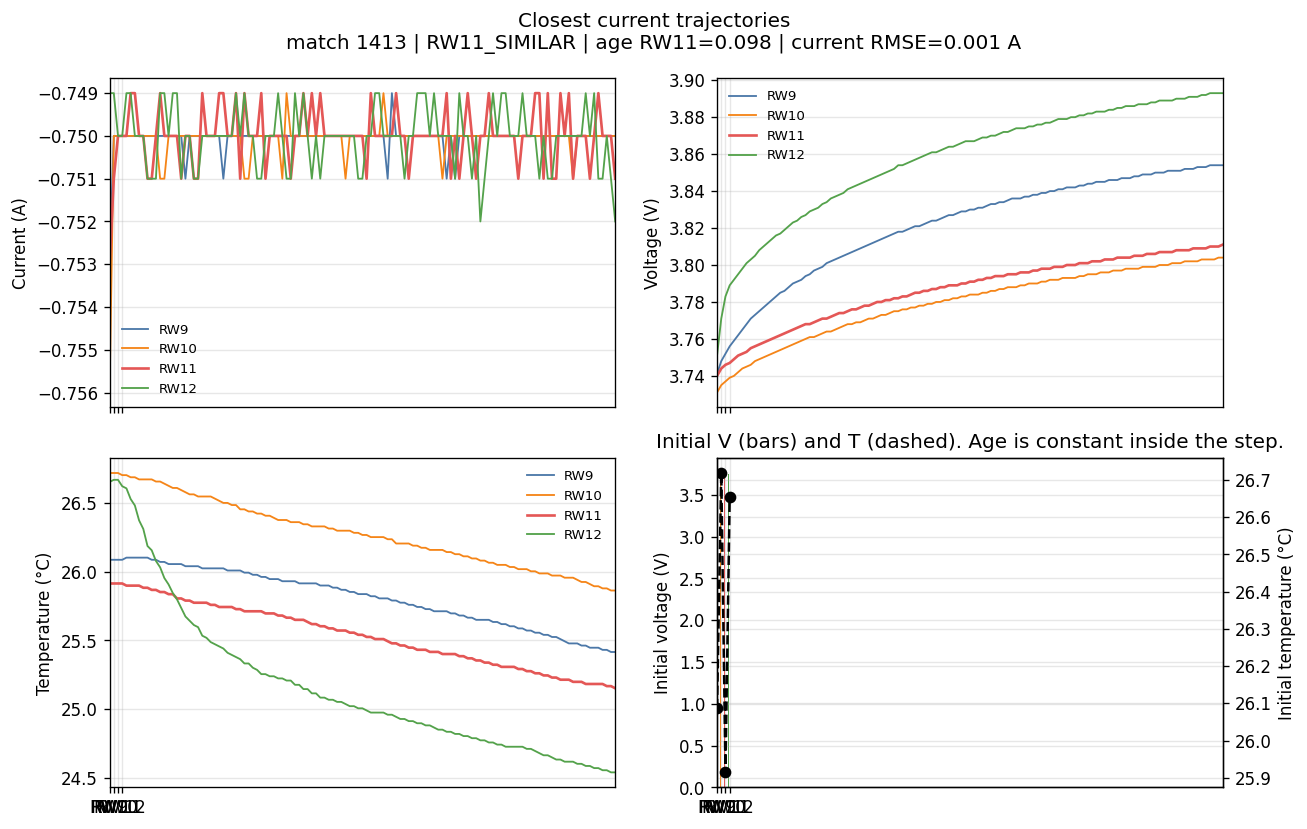

Saved /data/battery_RW_NASA/eda/figures/rw11_match_most_similar.png


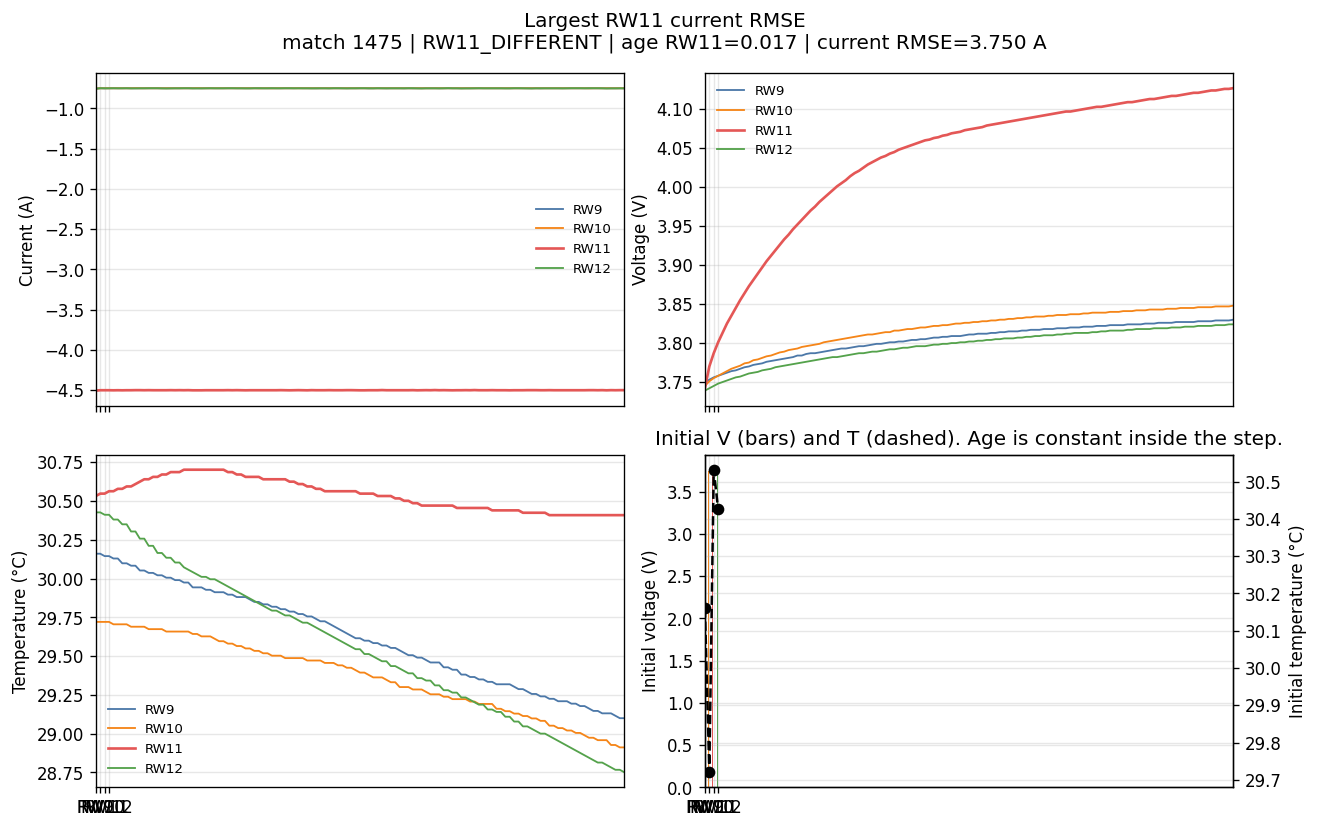

Saved /data/battery_RW_NASA/eda/figures/rw11_match_most_different.png


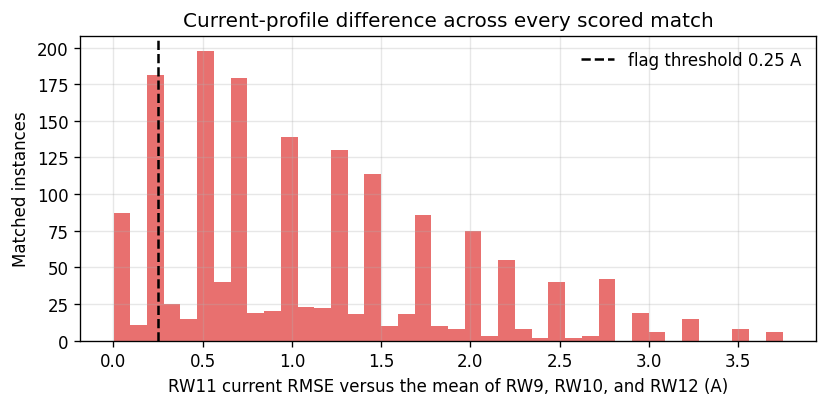

In [9]:
def _plot_case(match_id: int, title: str, path: Path) -> None:
    row = matches.loc[matches["match_id"] == match_id].iloc[0]
    fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
    series_names = [("current", "Current (A)"), ("voltage", "Voltage (V)"), ("temperature", "Temperature (°C)")]
    local = {cell: int(row[f"{cell}_local"]) for cell in CELLS}
    panels = [
        (axes[0, 0], "current", "Current (A)"),
        (axes[0, 1], "voltage", "Voltage (V)"),
        (axes[1, 0], "temperature", "Temperature (°C)"),
    ]
    for ax, key, ylabel in panels:
        for cell in CELLS:
            y = WINDOWS[cell][key][local[cell]]
            ax.plot(GRID, y, color=CELL_COLOR[cell], lw=1.6 if cell == "RW11" else 1.1, label=cell)
        ax.set_ylabel(ylabel)
        ax.set_xlim(0, FUTURE_WINDOW_S)
        ax.legend(frameon=False, fontsize=8)
    ages = [row[f"Age_initial_{cell}"] for cell in CELLS]
    voltages = [row[f"V_initial_{cell}"] for cell in CELLS]
    temps = [row[f"T_initial_{cell}"] for cell in CELLS]
    x = np.arange(len(CELLS))
    axes[1, 1].bar(x - 0.2, voltages, width=0.2, color=[CELL_COLOR[c] for c in CELLS])
    ax_t = axes[1, 1].twinx()
    ax_t.plot(x, temps, "k--", marker="o", label="T initial")
    axes[1, 1].set_xticks(x, CELLS)
    axes[1, 1].set_ylabel("Initial voltage (V)")
    ax_t.set_ylabel("Initial temperature (°C)")
    axes[1, 1].set_title("Initial V (bars) and T (dashed). Age is constant inside the step.")
    fig.suptitle(
        f"{title}\nmatch {match_id} | {row['RW11_flag']} | "
        f"age RW11={row['Age_initial_RW11']:.3f} | "
        f"current RMSE={row['RW11_current_rmse_A']:.3f} A"
    )
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.show()
    print("Saved", path)


scored = matches[matches["RW11_flag"] != "INSUFFICIENT_OVERLAP"].copy()
if len(scored):
    similar_id = int(scored.loc[scored["RW11_current_rmse_A"].idxmin(), "match_id"])
    different_id = int(scored.loc[scored["RW11_current_rmse_A"].idxmax(), "match_id"])
    _plot_case(similar_id, "Closest current trajectories", FIGURE_DIR / "rw11_match_most_similar.png")
    _plot_case(different_id, "Largest RW11 current RMSE", FIGURE_DIR / "rw11_match_most_different.png")
else:
    print("No match had enough overlapping samples to plot a current comparison.")

fig, ax = plt.subplots(figsize=(7, 3.5))
if len(scored):
    ax.hist(scored["RW11_current_rmse_A"], bins=40, color="#E45756", alpha=0.85)
    ax.axvline(RW11_CURRENT_RMSE_A, color="k", ls="--", label=f"flag threshold {RW11_CURRENT_RMSE_A} A")
    ax.legend(frameon=False)
ax.set_xlabel("RW11 current RMSE versus the mean of RW9, RW10, and RW12 (A)")
ax.set_ylabel("Matched instances")
ax.set_title("Current-profile difference across every scored match")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "rw11_current_rmse_hist.png", bbox_inches="tight")
plt.show()


## 10. Voltage and temperature comparison

The same two matches plot voltage and temperature against relative time. The histograms below cover every scored match, using RW11 against the mean of the other three cells on the overlap prefix.


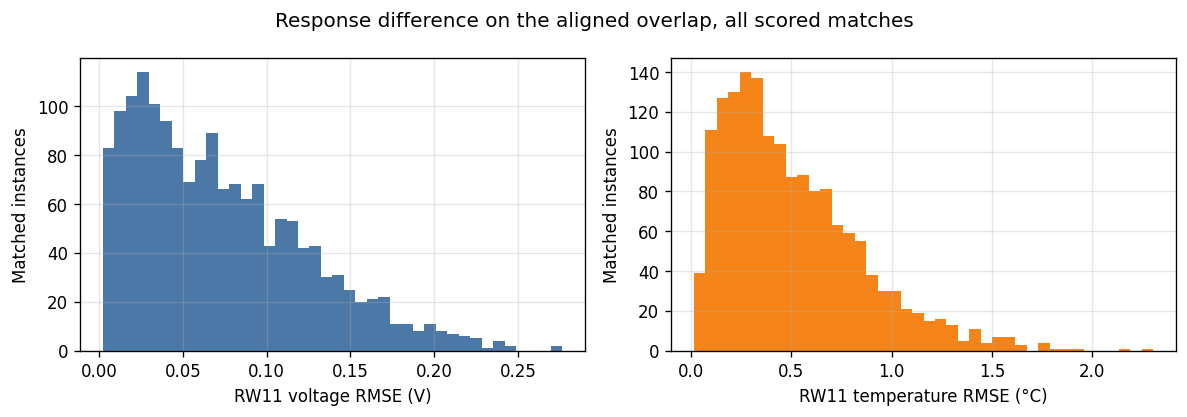

Median RMSE | current 1.0 A | voltage 0.0635 V | temperature 0.429 °C


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
if len(scored):
    axes[0].hist(scored["RW11_voltage_rmse_V"].dropna(), bins=40, color="#4C78A8")
    axes[1].hist(scored["RW11_temperature_rmse_C"].dropna(), bins=40, color="#F58518")
axes[0].set_xlabel("RW11 voltage RMSE (V)")
axes[1].set_xlabel("RW11 temperature RMSE (°C)")
for ax in axes:
    ax.set_ylabel("Matched instances")
fig.suptitle("Response difference on the aligned overlap, all scored matches")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "rw11_voltage_temperature_rmse_hist.png", bbox_inches="tight")
plt.show()
print(
    "Median RMSE | current",
    round(float(scored["RW11_current_rmse_A"].median()), 3) if len(scored) else "n/a",
    "A | voltage",
    round(float(scored["RW11_voltage_rmse_V"].median()), 4) if len(scored) else "n/a",
    "V | temperature",
    round(float(scored["RW11_temperature_rmse_C"].median()), 3) if len(scored) else "n/a",
    "°C",
)


## 11. RW11 deviation analysis

`RW11_DIFFERENT` means the overlap current is more than 0.25 A RMSE from the mean of the other three cells, or the mean current differs by more than 0.25 A. `RW11_SIMILAR` means neither of those. `INSUFFICIENT_OVERLAP` is excluded from the percentage.

The region table asks whether that current difference piles up in one voltage, temperature, or age band. Duration is a separate flag, because the random-walk steps are not the same length on every cell even when the current level matches.


In [11]:
n_scored = int((matches["RW11_flag"] != "INSUFFICIENT_OVERLAP").sum())
n_different = int((matches["RW11_flag"] == "RW11_DIFFERENT").sum())
n_similar = int((matches["RW11_flag"] == "RW11_SIMILAR").sum())
n_short = int((matches["RW11_flag"] == "INSUFFICIENT_OVERLAP").sum())
pct_different = 100.0 * n_different / n_scored if n_scored else np.nan
n_exact = int((matches["match_type"] == "exact").sum())
n_duration = int(matches["duration_different"].sum()) if len(matches) else 0

print(f"Scored matches: {n_scored}")
print(f"RW11_SIMILAR: {n_similar}")
print(f"RW11_DIFFERENT: {n_different} ({pct_different:.1f}% of scored)" if n_scored else "No scored matches")
print(f"INSUFFICIENT_OVERLAP: {n_short}")
print(f"Exact-band matches among the kept quadruples: {n_exact}")
print(f"Matches whose RW11 duration differs by more than {DURATION_DIFF_S:.0f} s: {n_duration}")

level_gap = (matches["n_current_levels_RW11"] - matches[["n_current_levels_RW9", "n_current_levels_RW10", "n_current_levels_RW12"]].median(axis=1)).abs()
print(f"Matches where RW11 has a different current-level count from the other-cell median: {int((level_gap > 0).sum())}")

def _region_table(frame: pd.DataFrame, column: str, edges: list[float], label: str) -> pd.DataFrame:
    scored_frame = frame[frame["RW11_flag"] != "INSUFFICIENT_OVERLAP"].copy()
    bins = pd.cut(scored_frame[column], bins=edges, include_lowest=True)
    rows = []
    for interval, part in scored_frame.groupby(bins, observed=False):
        n = len(part)
        n_diff = int((part["RW11_flag"] == "RW11_DIFFERENT").sum())
        rows.append({
            label: str(interval),
            "n_scored": n,
            "n_RW11_DIFFERENT": n_diff,
            "percent_different": 100.0 * n_diff / n if n else np.nan,
            "median_current_rmse_A": part["RW11_current_rmse_A"].median() if n else np.nan,
        })
    return pd.DataFrame(rows)

if n_scored:
    print("\nBy initial voltage (RW11)")
    display(_region_table(matches, "V_initial_RW11", [3.2, 3.7, 3.9, 4.05, 4.2, 4.7], "V_initial").round(2))
    print("By initial temperature (RW11)")
    display(_region_table(matches, "T_initial_RW11", [18, 24, 28, 32, 36, 48], "T_initial").round(2))
    print("By age (RW11)")
    display(_region_table(matches, "Age_initial_RW11", [0, 0.05, 0.1, 0.2, 0.5, 1.01], "age").round(2))


Scored matches: 1637
RW11_SIMILAR: 190
RW11_DIFFERENT: 1447 (88.4% of scored)
INSUFFICIENT_OVERLAP: 366
Exact-band matches among the kept quadruples: 0
Matches whose RW11 duration differs by more than 30 s: 763
Matches where RW11 has a different current-level count from the other-cell median: 1466

By initial voltage (RW11)


,V_initial,n_scored,n_RW11_DIFFERENT,percent_different,median_current_rmse_A
0,"(3.1990000000000003, 3.7]",162,115,70.99,0.50
1,"(3.7, 3.9]",612,537,87.75,1.00
2,"(3.9, 4.05]",664,614,92.47,1.25
3,"(4.05, 4.2]",199,181,90.95,0.57
4,"(4.2, 4.7]",0,0,NaN,NaN


By initial temperature (RW11)


,T_initial,n_scored,n_RW11_DIFFERENT,percent_different,median_current_rmse_A
0,"(17.999, 24.0]",18,16,88.89,1.12
1,"(24.0, 28.0]",675,608,90.07,1.00
2,"(28.0, 32.0]",841,744,88.47,1.00
3,"(32.0, 36.0]",103,79,76.70,0.75
4,"(36.0, 48.0]",0,0,NaN,NaN


By age (RW11)


,age,n_scored,n_RW11_DIFFERENT,percent_different,median_current_rmse_A
0,"(-0.001, 0.05]",578,503,87.02,1.00
1,"(0.05, 0.1]",545,476,87.34,0.86
2,"(0.1, 0.2]",441,400,90.70,1.00
3,"(0.2, 0.5]",61,56,91.80,1.25
4,"(0.5, 1.01]",12,12,100.00,1.25


## 12. Summary tables

The diagnostic table compares the whole charge-step population, then the matched subset. `RW11 deviation?` uses an absolute gap against the mean of RW9, RW10, and RW12: 0.02 V, 1.0 °C, and 0.02 age for the initial-condition rows (the same tolerances as the match), 0.25 A for current, and 30 s for duration. A near-zero spread among the other three cells does not by itself count as a deviation. Current, voltage, and temperature RMSE are RW11 against the mean of the other three, so those cells share one reference and RW11 holds the residual.


In [12]:
def _cell_mean(column_prefix: str) -> dict:
    return {cell: float(INSTANCES[cell][column_prefix].mean()) for cell in CELLS}

population_v = _cell_mean("V_initial")
population_t = _cell_mean("T_initial")
population_age = _cell_mean("age_initial")
population_i = _cell_mean("I_abs_mean")
population_peak = _cell_mean("I_abs_max")
population_dur = _cell_mean("duration_s")

matched_means = {}
for quantity, prefix in [
    ("V", "V_initial_"),
    ("T", "T_initial_"),
    ("age", "Age_initial_"),
    ("I", "I_abs_mean_"),
    ("peak", "I_abs_max_"),
    ("dur", "duration_s_"),
]:
    matched_means[quantity] = {
        cell: float(matches[f"{prefix}{cell}"].mean()) if len(matches) else np.nan
        for cell in CELLS
    }

rmse_ref = {
    "current": float(scored["RW11_current_rmse_A"].mean()) if len(scored) else np.nan,
    "voltage": float(scored["RW11_voltage_rmse_V"].mean()) if len(scored) else np.nan,
    "temperature": float(scored["RW11_temperature_rmse_C"].mean()) if len(scored) else np.nan,
}

def _dev(values: dict, threshold: float) -> str:
    rw11 = values["RW11"]
    others = np.array([values[cell] for cell in OTHERS], dtype=float)
    if not np.isfinite(rw11) or not np.isfinite(others).all():
        return "unclear"
    gap = abs(rw11 - float(np.mean(others)))
    return "no" if gap <= threshold else "yes"

diagnostic_rows = [
    ["Number of charge instances", *[len(INSTANCES[c]) for c in CELLS], "—"],
    ["Matched initial conditions (exclusive)", *[len(used[c]) for c in CELLS], "—"],
    ["Mean initial V, all charge steps", *[round(population_v[c], 3) for c in CELLS], _dev(population_v, TOL_VOLTAGE_V)],
    ["Mean initial V, matched only", *[round(matched_means["V"][c], 3) for c in CELLS], _dev(matched_means["V"], TOL_VOLTAGE_V)],
    ["Mean initial T, all charge steps (°C)", *[round(population_t[c], 2) for c in CELLS], _dev(population_t, TOL_TEMPERATURE_C)],
    ["Mean initial T, matched only (°C)", *[round(matched_means["T"][c], 2) for c in CELLS], _dev(matched_means["T"], TOL_TEMPERATURE_C)],
    ["Mean initial age, all charge steps", *[round(population_age[c], 3) for c in CELLS], _dev(population_age, TOL_AGE)],
    ["Mean initial age, matched only", *[round(matched_means["age"][c], 3) for c in CELLS], _dev(matched_means["age"], TOL_AGE)],
    ["Mean |current| on the full step (A)", *[round(population_i[c], 3) for c in CELLS], _dev(population_i, RW11_MEAN_CURRENT_DIFF_A)],
    ["Mean |current|, matched steps (A)", *[round(matched_means["I"][c], 3) for c in CELLS], _dev(matched_means["I"], RW11_MEAN_CURRENT_DIFF_A)],
    ["Mean peak |current|, matched steps (A)", *[round(matched_means["peak"][c], 3) for c in CELLS], _dev(matched_means["peak"], RW11_MEAN_CURRENT_DIFF_A)],
    ["Mean charge duration, matched steps (s)", *[round(matched_means["dur"][c], 1) for c in CELLS], _dev(matched_means["dur"], DURATION_DIFF_S)],
    ["Mean current RMSE of RW11 vs other-cell mean (A)", *["—", "—", round(rmse_ref["current"], 3), "—"], "yes" if np.isfinite(rmse_ref["current"]) and rmse_ref["current"] > RW11_CURRENT_RMSE_A else "no"],
    ["Mean voltage RMSE of RW11 vs other-cell mean (V)", *["—", "—", round(rmse_ref["voltage"], 4), "—"], "see conclusion"],
    ["Mean temperature RMSE of RW11 vs other-cell mean (°C)", *["—", "—", round(rmse_ref["temperature"], 3), "—"], "see conclusion"],
]
diagnostic = pd.DataFrame(diagnostic_rows, columns=["Diagnostic", "RW9", "RW10", "RW11", "RW12", "RW11 deviation?"])
display(diagnostic)
diagnostic.to_csv(OUTPUT_DIR / "rw11_diagnostic_summary.csv", index=False)
print("Wrote", OUTPUT_DIR / "rw11_diagnostic_summary.csv")


,Diagnostic,RW9,RW10,RW11,RW12,RW11 deviation?
0,Number of charge instances,23416,23159,22759.0000,21693,—
1,Matched initial conditions (exclusive),2003,2003,2003.0000,2003,—
2,"Mean initial V, all charge steps",3.962,3.964,3.9610,3.986,no
3,"Mean initial V, matched only",3.937,3.937,3.9370,3.937,no
4,"Mean initial T, all charge steps (°C)",34.59,33.99,26.1100,26.65,yes
5,"Mean initial T, matched only (°C)",28.47,28.5,28.3900,28.44,no
6,"Mean initial age, all charge steps",0.486,0.485,0.4860,0.486,no
7,"Mean initial age, matched only",0.093,0.093,0.0940,0.093,no
8,Mean |current| on the full step (A),2.393,2.399,2.4000,2.315,no
9,"Mean |current|, matched steps (A)",2.416,2.459,2.8050,2.284,yes


Wrote /data/battery_RW_NASA/eda/outputs/rw11_diagnostic_summary.csv


## 13. Diagnostic conclusion

The paragraph below is filled from the tables in this run. It describes the matched subset only. It does not say that a current difference caused the optimization result.


In [13]:
def _sentence() -> str:
    if not n_scored:
        return (
            "No charge quadruple had enough overlapping samples to compare future current. "
            "The available data do not answer whether RW11 follows a different current trajectory."
        )
    head = (
        f"Among {n_scored} charge instances with initial voltage within {TOL_VOLTAGE_V:.2f} V, "
        f"temperature within {TOL_TEMPERATURE_C:.1f} °C, and age within {TOL_AGE:.2f} "
        f"({n_exact} of the kept quadruples also sit in the stricter exact band), "
        f"RW11 shows {pct_different:.1f}% of cases with a distinct future-current trajectory "
        f"compared with the mean of RW9, RW10, and RW12."
    )
    parts = [head]
    if pct_different >= 20:
        parts.append(
            "The difference shows up in the current profile itself: the overlap RMSE or the mean current "
            f"exceeds {RW11_CURRENT_RMSE_A:.2f} A."
        )
    else:
        parts.append(
            "On the aligned overlap, RW11's current usually stays within "
            f"{RW11_CURRENT_RMSE_A:.2f} A of the other three cells, so a systematic current-shape split "
            "is not supported at this threshold."
        )
    if n_duration / max(len(matches), 1) >= 0.2:
        parts.append(
            f"Segment length still differs: {n_duration} matches have an RW11 duration more than "
            f"{DURATION_DIFF_S:.0f} s away from the median of the other three. "
            "That can change how long a current is held without changing the current level."
        )
    med_v = float(scored["RW11_voltage_rmse_V"].median()) if len(scored) else np.nan
    med_t = float(scored["RW11_temperature_rmse_C"].median()) if len(scored) else np.nan
    parts.append(
        f"Median voltage RMSE is {med_v:.3f} V and median temperature RMSE is {med_t:.2f} °C "
        "on the same overlap."
    )
    # Population temperature is the clearest unmatched data difference.
    t_gap = population_t["RW11"] - np.mean([population_t[c] for c in ["RW9", "RW10"]])
    age_med = float(matches["Age_initial_RW11"].median()) if len(matches) else np.nan
    age_early = float((matches["Age_initial_RW11"] < 0.2).mean()) if len(matches) else np.nan
    i_gap = float(matched_means["I"]["RW11"] - np.mean([matched_means["I"][c] for c in OTHERS]))
    parts.append(
        f"Before matching, RW11's mean initial temperature is {population_t['RW11']:.1f} °C, "
        f"{t_gap:.1f} °C relative to the RW9/RW10 average. "
        "The match forces temperature into the tolerance, so that population gap is not the matched-current result. "
        f"Because RW9 and RW10 run hotter later, the kept matches sit early in life: median RW11 age {age_med:.3f}, "
        f"and {100 * age_early:.0f}% of matches have age below 0.20. "
        "Inside that overlap the current gap is not confined to one voltage or age bin. "
        f"RW11's mean absolute current on the matched steps is {i_gap:+.2f} A relative to the mean of the other three. "
        "Duplicate timestamps and NaNs are rare in the quality table, which does not point to a recording failure "
        "as the main explanation."
    )
    if pct_different < 20 and n_duration / max(len(matches), 1) >= 0.2:
        parts.append(
            "What remains visible is mainly a difference in charging-segment length, not a different current step, "
            "and it is not clearly distinguishable from the random-walk schedule each cell was given."
        )
    elif pct_different >= 20:
        parts.append(
            "The current-profile gap remains after the initial voltage, temperature, and age are aligned, "
            "so it is not explained by those initial conditions alone. This does not identify a cause."
        )
    else:
        parts.append(
            "With these tolerances, the future current of RW11 is not clearly distinguishable from RW9, RW10, and RW12."
        )
    return " ".join(parts)

conclusion = _sentence()
print(conclusion)
(OUTPUT_DIR / "rw11_diagnostic_conclusion.txt").write_text(conclusion + "\n", encoding="utf-8")
print("Wrote", OUTPUT_DIR / "rw11_diagnostic_conclusion.txt")


Among 1637 charge instances with initial voltage within 0.02 V, temperature within 1.0 °C, and age within 0.02 (0 of the kept quadruples also sit in the stricter exact band), RW11 shows 88.4% of cases with a distinct future-current trajectory compared with the mean of RW9, RW10, and RW12. The difference shows up in the current profile itself: the overlap RMSE or the mean current exceeds 0.25 A. Segment length still differs: 763 matches have an RW11 duration more than 30 s away from the median of the other three. That can change how long a current is held without changing the current level. Median voltage RMSE is 0.064 V and median temperature RMSE is 0.43 °C on the same overlap. Before matching, RW11's mean initial temperature is 26.1 °C, -8.2 °C relative to the RW9/RW10 average. The match forces temperature into the tolerance, so that population gap is not the matched-current result. Because RW9 and RW10 run hotter later, the kept matches sit early in life: median RW11 age 0.074, and 

## 14. Example trajectories

Six `RW11_DIFFERENT` and six `RW11_SIMILAR` matches, spread across initial voltage. Time is relative to the start of the charge step and resampled at 1 s for 120 s, the same alignment as the rest of this notebook. Current keeps the sign stored in the Matlab file (charge steps are negative).

`RW11_SIMILAR` here also requires the four window-mean currents to lie within 0.35 A of each other, so the panel is not a case where RW11 merely sits near the average of three disagreeing cells.

![RW11 different gallery](figures/rw11_different_gallery.png)

![RW11 similar gallery](figures/rw11_similar_gallery.png)

Same initial V, T, and age, and the same future current. Only 37 matched quadruples have all four window-mean currents within 0.15 A; the six below are one case at each shared level (two at 0.75 A, at a low and a high voltage). The current axis is shared so a common level reads as one line.

![Same current gallery](figures/rw11_same_current_gallery.png)

Individual panels are in `figures/rw11_same_current/`. Match ids are in `outputs/rw11_same_current_cases.csv`.